# Predict circuit quality and cost before you run it

`qward.qaqs` estimates how well a circuit will run on **IBM Fez** and **IBM Kingston**, and what the job will cost, *before* you spend any QPU time. It uses only the circuit itself: QWARD computes the circuit's **footprint** (a set of pre-runtime metrics of the logical and the compiled circuit) and frozen models trained on 2,409 real executions turn it into predictions.

The models come from the thesis *Estimating the quality of quantum circuits before execution*. They ship inside QWARD as plain JSON and run on NumPy, so there is nothing to download and no pickled code to trust.

```bash
pip install qiskit-qward              # footprint + predictions
pip install "qiskit-qward[torch]"     # optional: quantum-specific metrics (PyTorch)
```

In [1]:
import warnings
warnings.filterwarnings("ignore")

from qiskit import QuantumCircuit
from qiskit.circuit.library import QFTGate
from qiskit_ibm_runtime.fake_provider import FakeFez, FakeKingston

from qward.qaqs import predict, model_card

## 1. A circuit

A 6-qubit GHZ state. Any `QuantumCircuit` works; measurements should be included.

In [2]:
def ghz(n):
    qc = QuantumCircuit(n, n)
    qc.h(0)
    for i in range(n - 1):
        qc.cx(i, i + 1)
    qc.measure(range(n), range(n))
    return qc

circuit = ghz(6)
circuit.draw("text", fold=100)

┌───┐          ┌─┐                              
q_0: ┤ H ├──■───────┤M├──────────────────────────────
     └───┘┌─┴─┐     └╥┘     ┌─┐                      
q_1: ─────┤ X ├──■───╫──────┤M├──────────────────────
          └───┘┌─┴─┐ ║      └╥┘     ┌─┐              
q_2: ──────────┤ X ├─╫───■───╫──────┤M├──────────────
               └───┘ ║ ┌─┴─┐ ║      └╥┘     ┌─┐      
q_3: ────────────────╫─┤ X ├─╫───■───╫──────┤M├──────
                     ║ └───┘ ║ ┌─┴─┐ ║      └╥┘┌─┐   
q_4: ────────────────╫───────╫─┤ X ├─╫───■───╫─┤M├───
                     ║       ║ └───┘ ║ ┌─┴─┐ ║ └╥┘┌─┐
q_5: ────────────────╫───────╫───────╫─┤ X ├─╫──╫─┤M├
                     ║       ║       ║ └───┘ ║  ║ └╥┘
c: 6/════════════════╩═══════╩═══════╩═══════╩══╩══╩═
                     0       1       2       3  4  5

## 2. Predict

`predict(circuit, backend)` compiles the circuit for the backend (optimization level 3, the setting used for all training data), computes the footprint and applies the models.

The backend can be a **real** IBM backend (`service.backend("ibm_fez")`) or a fake one such as `FakeFez()`. A real backend reproduces exactly what will run; a fake one is close (two-qubit gate counts matched the real chips on every validation circuit, compiled depth differed by up to about 12%). This notebook uses fake backends so it runs offline.

In [3]:
result = predict(circuit, FakeFez())
result.warnings

('no barrier found: added one before the final measurements, as in every training circuit (the footprint is sensitive to it; pass add_barrier=False to predict the circuit as given)',
 'compiled for a fake backend: two-qubit gate counts matched the real chips in validation, but compiled depth can differ by up to ~12%; use a real backend for the closest footprint')

### Quality predictions

Each prediction carries the score of its own model on **circuits it had never seen** (the thesis validation), so you can judge how much to trust it. On circuits the models had never seen, success rate, Hellinger fidelity and TVD scored R² between 0.90 and 0.94 on the chip they were trained on (some confidence intervals still straddle the 0.80 threshold, hence *inconclusive*); DSR scored 0.05 to 0.29 and is flagged.

In [4]:
import pandas as pd

table = pd.DataFrame(result.quality_table())
table["prediction"] = table["prediction"].round(3)
table["validation_r2"] = table["validation_r2"].round(2)
table[["chip", "target", "prediction", "validation_r2", "verdict", "warnings"]]

,chip,target,prediction,validation_r2,verdict,warnings
0,ibm_fez,success,0.907,0.94,pass,
1,ibm_fez,hellinger,0.907,0.90,pass,
2,ibm_fez,tvd,0.097,0.92,inconclusive,
3,ibm_fez,dsr,0.936,0.05,inconclusive,DSR predictions missed the thesis threshold (R...
4,ibm_kingston,success,0.934,0.93,pass,
5,ibm_kingston,hellinger,0.868,0.92,inconclusive,
6,ibm_kingston,tvd,0.070,0.94,pass,
7,ibm_kingston,dsr,0.966,0.29,fail,DSR predictions missed the thesis threshold (R...


Success rate and Hellinger fidelity are better when higher; TVD (total variation distance) is better when lower. `verdict` is the outcome of the thesis' new-run test against R² ≥ 0.80: *pass*, *fail*, or *inconclusive* when the confidence interval straddles the threshold.

### Cost

IBM bills QPU time in resource units (RU): 1 RU = 1 minute of QPU time, charged in whole seconds rounded up. The cost model was validated at **1,024 shots**.

In [5]:
c = result.cost
print(f"predicted billed time : {c.seconds:.3f} s  ->  {c.resource_units:.4f} RU  (charged as {c.billed_seconds} s)")
print(f"IBM's rule of thumb   : {c.ibm_rule_seconds:.3f} s")
print(f"typical error         : about {c.mae_seconds * 1000:.0f} ms on new runs")

predicted billed time : 1.968 s  ->  0.0328 RU  (charged as 2 s)
IBM's rule of thumb   : 2.358 s
typical error         : about 3 ms on new runs


Most of that bill is a fixed per-job overhead of about 1.7 s; the circuit itself runs for a fraction of a second. Cost therefore barely changes between small circuits and grows with the scheduled duration of the circuit and with the number of shots. Other shot counts are an *extrapolation* of IBM's usage formula, not a validated result, and `predict` says so:

In [6]:
from qward.qaqs import predict_cost

for shots in (1024, 4096, 16384):
    p = predict_cost(result.footprint, shots=shots)
    print(f"{shots:>6} shots: {p.seconds:6.2f} s = {p.resource_units:.4f} RU", "(extrapolated)" if p.warnings else "")

  1024 shots:   1.97 s = 0.0328 RU 
  4096 shots:   2.77 s = 0.0461 RU (extrapolated)
 16384 shots:   5.97 s = 0.0994 RU (extrapolated)


## 3. The footprint

The footprint is the evidence behind every prediction: metrics of the logical circuit (`a.*`) and of the compiled circuit (`b.*`). Names match the thesis dataset. These are the metrics the Fez and Kingston success-rate models use:

In [7]:
fp = pd.Series(result.footprint)
used = sorted(set(load_features for load_features in
    model_card("ibm_fez/success").features + model_card("ibm_kingston/success").features))
fp[used].to_frame("value")

,value
a.ComplexityMetrics.gate_based_metrics.multi_qubit_ratio,0.333
a.ComplexityMetrics.standardized_metrics.gate_density,0.31
a.ElementMetrics.percent_qm,1.0
a.quantum_specific.magic,0.0
b.BehavioralMetrics.critical_depth,1.0
b.BehavioralMetrics.measurement,0.05
b.ComplexityMetrics.derived_metrics.square_ratio,0.316
b.ComplexityMetrics.entanglement_metrics.entangling_width,6.0
b.ComplexityMetrics.gate_based_metrics.multi_qubit_ratio,0.385
b.ComplexityMetrics.standardized_metrics.circuit_volume,114.0


## 4. Compare with what real hardware did

The thesis ran 2,409 jobs on Fez and Kingston plus 252 validation jobs on Fez, Kingston and the never-seen Marrakesh. For circuits that were measured, the predictions can be checked directly. Measured success rates below are the mean over repeated runs (thesis dataset).

In [8]:
measured = {  # mean success rate over repeated runs on the real chips
    ("GHZ 6", "ibm_fez"): 0.909,       ("GHZ 6", "ibm_kingston"): 0.887,
    ("GHZ 10", "ibm_fez"): 0.818,      ("GHZ 10", "ibm_kingston"): 0.837,
    ("QFT round trip, 4 qubits", "ibm_fez"): 0.748, ("QFT round trip, 4 qubits", "ibm_kingston"): 0.855,
}

def qft_roundtrip(n):
    qc = QuantumCircuit(n, n)
    for i in range(0, n, 2):
        qc.x(i)
    qc.barrier()
    qc.append(QFTGate(n), range(n))
    qc.barrier()
    qc.append(QFTGate(n).inverse(), range(n))
    qc.barrier()
    qc.measure(range(n), range(n))
    return qc

backends = {"ibm_fez": FakeFez(), "ibm_kingston": FakeKingston()}
rows = []
for name, qc in [("GHZ 6", ghz(6)), ("GHZ 10", ghz(10)), ("QFT round trip, 4 qubits", qft_roundtrip(4))]:
    for chip, backend in backends.items():
        r = predict(qc, backend, chips=(chip,), targets=("success",), quantum_specific_metrics=False)
        rows.append({"circuit": name, "chip": chip,
                     "predicted": round(r.quality[f"{chip}/success"].value, 3),
                     "measured": measured[(name, chip)]})
comparison = pd.DataFrame(rows)
comparison["error"] = (comparison["predicted"] - comparison["measured"]).round(3)
comparison

,circuit,chip,predicted,measured,error
0,GHZ 6,ibm_fez,0.907,0.909,-0.002
1,GHZ 6,ibm_kingston,0.934,0.887,0.047
2,GHZ 10,ibm_fez,0.821,0.818,0.003
3,GHZ 10,ibm_kingston,0.862,0.837,0.025
4,"QFT round trip, 4 qubits",ibm_fez,0.707,0.748,-0.041
5,"QFT round trip, 4 qubits",ibm_kingston,0.727,0.855,-0.128


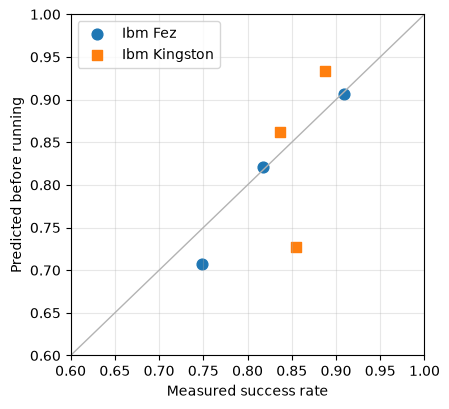

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for chip, marker in (("ibm_fez", "o"), ("ibm_kingston", "s")):
    d = comparison[comparison.chip == chip]
    ax.scatter(d.measured, d.predicted, marker=marker, s=60, label=chip.replace("ibm_", "IBM ").title())
ax.plot([0.6, 1], [0.6, 1], color="0.7", lw=1)
ax.set_xlim(0.6, 1); ax.set_ylim(0.6, 1)
ax.set_xlabel("Measured success rate"); ax.set_ylabel("Predicted before running")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Know when to doubt a prediction

`predict` warns when:

* the circuit is **larger than anything the model was trained on**. This is where the models failed in validation: they predict well for new circuits of familiar size, and poorly for much larger ones;
* a **model input is outside its training range**, so the circuit is unlike the training circuits;
* the **quantum-specific metrics** (PyTorch) were missing: the Fez models use them. They are computed up to 8 qubits (a few seconds at 6 qubits, over a minute at 8); beyond that, as in the training data, they are missing;
* the **target is DSR**, which missed the R² ≥ 0.80 threshold on new circuits.

A circuit with no barrier gets one added before its final measurements, because every training circuit had one and the footprint is sensitive to it.

In [10]:
wide = ghz(18)
r = predict(wide, FakeFez(), chips=("ibm_fez",), targets=("success",), cost=False, quantum_specific_metrics=False)
for w in r.quality["ibm_fez/success"].warnings:
    print("-", w)

- circuit has 18 qubits, more than the largest in training (16); predictions for larger circuits were not reliable in validation
- 2 model input(s) outside the range seen in training: b.ComplexityMetrics.standardized_metrics.gate_density = 0.125 (training 0.133 to 1.25); b.ComplexityMetrics.entanglement_metrics.entangling_width = 18 (training 1 to 16). The model has not seen circuits like this and the prediction may be unreliable
- quantum-specific metrics are missing (circuit above 8 qubits, dynamic, or PyTorch not installed); the model fills them with the training median


## What the models know

Every model has a card: what it was trained on, how it did on unseen circuits, and in the thesis' new-run test.

In [11]:
card = model_card("ibm_kingston/success")
print("model        :", card.model_name)
print("trained on   :", card.trained_on_jobs, "jobs")
print("unseen circuits (cross-validation): R2 =", round(card.unseen_circuit_r2, 3))
same = card.same_chip_new_circuits
print(f"new run, same chip              : R2 = {same['r2']:.2f}  [{same['r2CiLow']:.2f}, {same['r2CiHigh']:.2f}]  ({same['h1Verdict']})")
other = card.unseen_chip_new_circuits
print(f"new run, unseen chip (Marrakesh): R2 = {other['r2']:.2f}  [{other['r2CiLow']:.2f}, {other['r2CiHigh']:.2f}]  ({other['h1Verdict']})")

model        : SVR
trained on   : 1173 jobs
unseen circuits (cross-validation): R2 = 0.909
new run, same chip              : R2 = 0.93  [0.84, 0.98]  (pass)
new run, unseen chip (Marrakesh): R2 = 0.69  [0.41, 0.85]  (inconclusive)


### Using a real backend

```python
from qiskit_ibm_runtime import QiskitRuntimeService
backend = QiskitRuntimeService().backend("ibm_fez")
result = predict(circuit, backend)
```

With a real backend the footprint is computed on the circuit as the chip will actually run it.